Task 1 - Read Text and Work With It

This command allows you to open and download files from the internet using a URL.

I also decided to immediately display the first 1,000,000 characters of the text. This operation itself selects a portion of the text—from the beginning up to the 1,000,000th character.

In [13]:
import urllib.request

text = urllib.request.urlopen("https://www.gutenberg.org/cache/epub/59/pg59.txt").read().decode("utf-8")

print(text[:1000000])

The Project Gutenberg eBook of Discourse on the Method of Rightly Conducting One's Reason and of Seeking Truth in the Sciences
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Discourse on the Method of Rightly Conducting One's Reason and of Seeking Truth in the Sciences

Author: René Descartes

Translator: John Veitch


        
Release date: March 1, 1993 [eBook #59]
                Most recently updated: May 13, 2022

Language: English

Other information and formats: www.gutenberg.org/ebooks/59

Credits: Ilana and Greg Newby


*** START OF THE PROJECT GUTENBERG EBOOK DISCOURSE ON THE

The split() command separates the text into individual words and stores them in a list called words. It also handles multiple spaces between words. And this command prints the first 12 words from the text(the slicing operation [:12] selects the first 12 elements of the list).

In [16]:
words = text.split()

print(words[:12])

['The', 'Project', 'Gutenberg', 'eBook', 'of', 'Discourse', 'on', 'the', 'Method', 'of', 'Rightly', 'Conducting']


I decided to calculate the total number of words in the list separately using the len() function, and the print() command displayed the result along with the text "Number of words."

In [17]:
print("Number of words:", len(words))

Number of words: 26133


In this section, I decided to combine several commands to analyze the text.

First, I examined the initial letters of the first 12 words.
Next, following the approach used in class, I identified words consisting of five letters or fewer and displayed the first 38 of these.
After looking at the beginning, I decided to examine the words at the end of the text—specifically, the last 17 words in this dataset (if one might call it that).

Following this, I performed some additional checks, one of which involved creating a list containing the character count for each of the first 30 words.

Finally, I reversed the order of all the words in the list and displayed the first 40 words from the resulting sequence.

In [19]:
print([word[0] for word in words[:12]])

print([word for word in words if len(word) <= 5][:38])

print(words[-17:])

print([len(word) for word in words[:30]])

print(words[::-1][:40])

['T', 'P', 'G', 'e', 'o', 'D', 'o', 't', 'M', 'o', 'R', 'C']
['The', 'eBook', 'of', 'on', 'the', 'of', "One's", 'and', 'of', 'Truth', 'in', 'the', 'This', 'eBook', 'is', 'for', 'the', 'use', 'of', 'in', 'the', 'and', 'most', 'other', 'parts', 'of', 'the', 'world', 'at', 'no', 'cost', 'and', 'with', 'no', 'You', 'may', 'copy', 'it,']
['produce', 'our', 'new', 'eBooks,', 'and', 'how', 'to', 'subscribe', 'to', 'our', 'email', 'newsletter', 'to', 'hear', 'about', 'new', 'eBooks.']
[3, 7, 9, 5, 2, 9, 2, 3, 6, 2, 7, 10, 5, 6, 3, 2, 7, 5, 2, 3, 8, 4, 5, 2, 3, 3, 3, 2, 6, 8]
['eBooks.', 'new', 'about', 'hear', 'to', 'newsletter', 'email', 'our', 'to', 'subscribe', 'to', 'how', 'and', 'eBooks,', 'new', 'our', 'produce', 'help', 'to', 'how', 'Foundation,', 'Archive', 'Literary', 'Gutenberg', 'Project', 'the', 'to', 'donations', 'make', 'to', 'how', 'including', 'Gutenberg,', 'Project', 'about', 'information', 'includes', 'website', 'This', 'www.gutenberg.org.']


Task 2 - Create a Basic Word Cloud

Before you begin, you need to run a command to install the WordCloud library. It is used to create visual representations of text.

In [20]:
pip install wordcloud

I import the WordCloud library to generate the word cloud and matplotlib to display the image.

In [21]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

To begin with, I decided to create a simple "word cloud" based on the text. I also set the width and height parameters to 800 and 400, and chose to make the background pink.

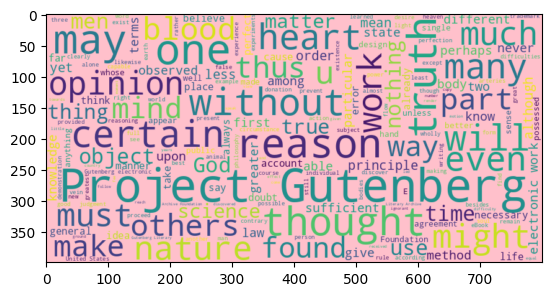

In [22]:
wc = WordCloud(width=800, height=400, background_color="pink").generate_from_text(text)
plt.imshow(wc, interpolation="bilinear")

plt.show()

Based on this cloud of words, one can conclude that the text touches upon philosophical questions regarding how an individual perceives reality, forms their own beliefs, and distinguishes truth from opinion.

I find the juxtaposition of terms such as "opinion," "truth," and "reason" particularly interesting. From a philosophical perspective, these may point to the problem of the reliability of knowledge—that is, the extent to which a person can be certain of their own judgments, and whether their opinions always correspond to the truth.

Furthermore, it is explicitly mentioned—and quite frequently—which project can be used to read this text.

Next, I decided to create a second word cloud to test a configuration where the color of each word depends on its length.

I set a condition: words with fewer than five characters appear in green, while those with five or more characters appear in blue. I also specified the dimensions of the cloud—800 by 400 pixels—and set the background color to orange.

Additionally, I included a parameter to exclude a predefined list of "stop words"(words that carry little to no significant meaning) from the cloud.

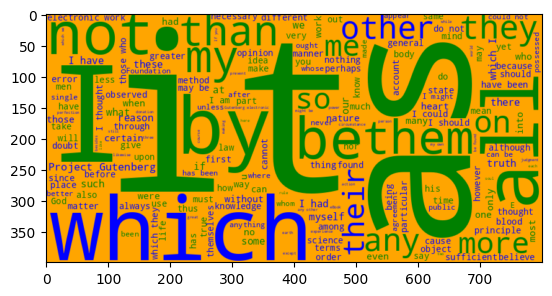

In [50]:
def color_function(word, font_size, position, orientation, random_state=None, **additional_args):
    if len(word) < 5:
        return "green"
    return "blue"

wc = WordCloud(width=800, height=400, background_color="orange", stopwords=stopwords_list).generate_from_text(text)

wc = wc.recolor(color_func=color_function)

plt.imshow(wc, interpolation="bilinear")

plt.show()

Looking at this word cloud, it’s safe to say that pronouns and conjunctions should always be removed, as they make up the vast majority of the content here.

That said, speaking from my own experience, I can tell you that this is definitely a philosophical text. If someone had simply shown me this word cloud and asked what kind of text it was, I would have confidently identified it as philosophical because that is, in fact, how such texts are typically written.

For my final word cloud, I decided to shape it like an open book, with the words forming the "cover."
Unfortunately, I wasn't able to use the method shown in class, as I kept running into an error.
Because of this, I opted for a different approach: embedding a PNG image directly into the code.
To do this, I included the necessary reference link required for this particular process.

In [65]:
text = urllib.request.urlopen("https://www.gutenberg.org/cache/epub/59/pg59.txt").read().decode("utf-8")

from google.colab import files
uploaded = files.upload()

Saving open-book2.png to open-book2 (5).png


I’ve moved the command for selecting a mask and specifying the file type from which to take an example of that mask into a separate field.

In [66]:
book_image = Image.open("open-book2.png")
mask = np.array(book_image)

In the final line of code, I specified the font settings and set the background color to white.
I also included two parameters to filter out words that might interfere with text analysis: I defined a list of "stop words" and manually removed other common English words that came to mind.
Additionally, I used the command `plt.axis("off")` to remove the coordinate axes from the image; this hides the axis lines, numerical values, and the horizontal and vertical tick marks.

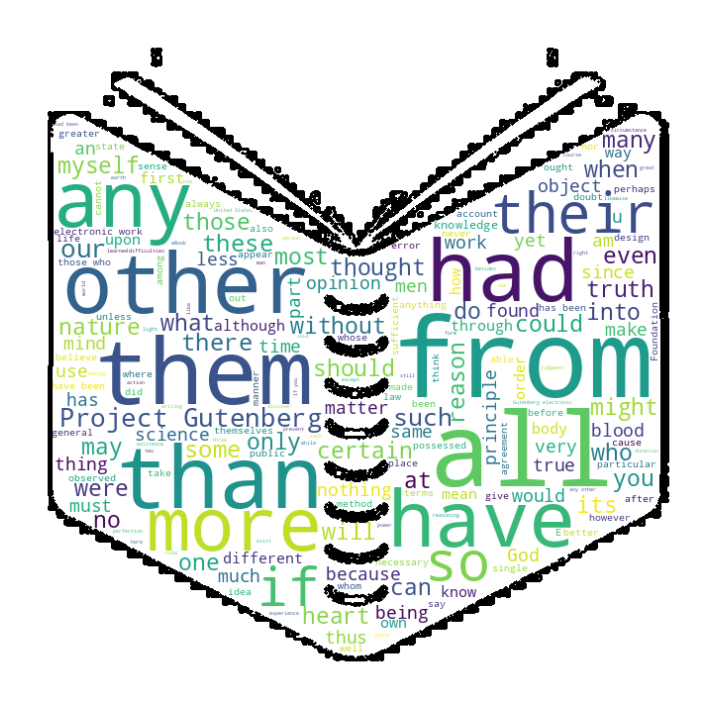

In [68]:
wc = WordCloud(width=1500,height=500, background_color="white", mask=mask, stopwords=stopwords_list, contour_width=2, contour_color="black").generate_from_text(text)
stopwords_list = urllib.request.urlopen("https://gist.githubusercontent.com/sebleier/554280/raw/7e0e4a1ce04c2bb7bd41089c9821dbcf6d0c786c/NLTK's%2520list%2520of%2520english%2520stopwords").read().decode("utf-8").split("\n")
stopwords_list = ["the", "and", "of", "to", "in", "a", "is", "that", "it", "for", "with", "was", "as", "but", "on","this", "be", "by", "which", "not", "my", "i",
                  "he", "his", "me", "we", "they", "or", "are"]
plt.figure(figsize=(14, 9))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")

plt.show()

Based on this cloud, it can be said that the text is of a reflective nature. There are many words indicating that the author spent a great deal of time reflecting and posing questions. Additionally, the text includes various exceptions or clarifications.
Furthermore, to reiterate a point from the previous cloud, there are numerous references to the project that digitized this work and made it publicly available.